<a href="https://colab.research.google.com/github/claudyanepmarinho/Streaming-de-filmes/blob/main/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Importações


In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

###Carregar os dados

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "filmes"   # ex.: "livros"
NOME_TABELA_FATO = "visualizacoes"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
filmes -> 10300 linhas
visualizacoes -> 55000 linhas


###Conhecendo a tabela dimensão

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10300 linhas e 7 colunas (variáveis)


,filme_id,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,Segredo Vale,animação,1991,85,L,Pietra Brito
1,2,Distante Destino,animação,2002,155,14,Luiz Miguel da Conceição
2,3,Dourado Deserto,ação,1995,128,L,Joaquim da Mota
3,4,Sombra Caminho,comédia,2016,120,16,Milena Cavalcante
4,5,Escarlate Vale,romance,1992,101,L,Marina Pimenta


###Conhecendo a tabela fato

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False


In [5]:
registro = df_dimensao.loc[df_dimensao["filme_id"] == 5000]
print(registro)

      filme_id               titulo genero  ano_lancamento  duracao_min  \
4999      5000  Segredo Jardim 4999   ação            1995           93   

     classificacao_indicativa        diretor  
4999                       16  Isabela Porto  


### Pergunta que eu quero responder:
Os usuários assistem aos filmes até o fim ou abandonam no meio?

###Tipos das colunas

In [6]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   visualizacao_id      55000 non-null  int64 
 1   filme_id             55000 non-null  int64 
 2   usuario_id           55000 non-null  int64 
 3   data_hora_inicio     55000 non-null  object
 4   tempo_assistido_min  55000 non-null  int64 
 5   dispositivo          55000 non-null  object
 6   concluido            55000 non-null  bool  
dtypes: bool(1), int64(4), object(2)
memory usage: 2.6+ MB


###Valores ausentes

In [7]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
visualizacao_id        0
filme_id               0
usuario_id             0
data_hora_inicio       0
tempo_assistido_min    0
dispositivo            0
concluido              0
dtype: int64


###Linhas duplicadas

In [8]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


###Chave estrangeira

In [9]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "filme_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "filme_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


###Checar a coluna numérica

In [10]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_assistido_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


###Medidas estatísticas

In [11]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,90.93
Mediana,88.00
Moda,74.00
Desvio padrão,35.26
Variância,1243.05
Mínimo,2.00
Máximo,183.00
Amplitude,181.00


Média - mediana: 2.93


#Insights
Tempo assistido

Refined-by: AI (ChatGPT)
AI-Refinement-Date: 2026-11-16

Média: O tempo médio assistido é de 90,93 minutos por visualização, indicando que os usuários permanecem, em média, cerca de 91 minutos consumindo conteúdo na plataforma.

Mediana: A mediana de 88 minutos está próxima da média, sugerindo que não há uma diferença expressiva entre essas duas medidas de tendência central.

Desvio padrão: O desvio padrão de 35,26 minutos indica uma variação considerável nos tempos assistidos, sugerindo diferentes padrões de consumo entre as visualizações.

Insight geral: Embora o tempo médio assistido seja de aproximadamente 91 minutos, existe uma dispersão relevante nos dados. É necessário comparar o tempo assistido com a duração dos filmes para avaliar melhor o comportamento de conclusão e abandono.

###Juntar a fato com a dimensão (JOIN)

In [12]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


###Comparar grupos por uma coluna da fato

In [13]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "dispositivo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
dispositivo,,,,
tablet,5581,92.08,89.0,35.03
console,2734,91.06,88.0,35.65
celular,16503,90.96,88.0,35.40
smart_tv,21994,90.86,88.0,35.29
computador,8188,90.21,87.0,34.89


**Leitura por dispositivo**
Refined-by: AI (ChatGPT)
AI-Refinement-Date: 2026-11-16

- Grupo com a maior média: Tablet, com 92,08 minutos. A mediana também é a maior (89 minutos), confirmando a posição desse grupo em relação aos demais.
- Grupo com o maior desvio padrão: Console, com 35,65 minutos, indicando que os tempos assistidos apresentam maior dispersão nesse grupo.
- Comparação das médias: As médias são muito próximas, variando de 90,21 a 92,08 minutos. Isso sugere que o dispositivo utilizado não está associado a diferenças expressivas no tempo médio de visualização.

###Comparar grupos por uma coluna da dimensão

In [14]:
COLUNA_GRUPO = "genero"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
genero,,,,
drama,10675,91.79,88.0,35.92
ficção científica,7340,91.63,87.0,36.15
romance,4893,91.26,88.0,34.72
comédia,7966,91.11,89.0,35.26
terror,5678,90.99,88.0,35.19
ação,8708,90.86,88.0,35.07
animação,5629,89.17,85.0,34.93
documentário,4111,89.10,87.0,33.31


**Leitura por gênero**

Refined-by: AI (ChatGPT)
AI-Refinement-Date: 2026-11-16



Grupo com a maior média: Drama, com 91,79 minutos. Entretanto, não há tanta variação com a menor média, que é de 89,10, referente ao gênero documentário.

Grupo com o maior desvio padrão: Ficção científica, com 36,15 minutos, indicando maior dispersão nos tempos assistidos desse grupo.

Comparação das médias: As médias são bastante próximas, variando de 89,10 a 91,79 minutos. Isso sugere que o gênero do filme não está associado a diferenças expressivas no tempo médio de visualização.

###Regra do IQR

In [15]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -11.50 a 192.50
Outliers: 0 de 55000 valores
Maiores valores: [183, 183, 183, 183, 183]
Menores valores: [2, 3, 4, 4, 5]


###Medidas com e sem os candidatos a outlier

In [16]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,90.93,90.93
Mediana,88.00,88.00
Desvio padrão,35.26,35.26


### Leitura e decisão registrada

- **Outliers:** A regra do IQR identificou 0 valores entre os 55.000 registros. Os limites calculados foram de -11,50 a 192,50 minutos. Como nenhum valor ultrapassou esses limites, não houve candidatos a outlier.
- **Impacto nas medidas:** Como nenhum registro foi identificado para exclusão, a média, a mediana e o desvio padrão permaneceram iguais na comparação com e sem os candidatos a outlier.

- **Decisão:** Manter todos os registros, pois nenhum outlier foi identificado pelo critério do IQR.

- **Valores ausentes:** Não houve valores ausentes (checagem na tabela fato).

###Assimetria (skew)

In [17]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 0.22


###Percentis

In [18]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     47.0
0.25     65.0
0.50     88.0
0.75    116.0
0.90    141.0
Name: tempo_assistido_min, dtype: float64


###Quantidade de valores por faixa

In [19]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_assistido_min,
"(1.819, 38.2]",3231
"(38.2, 74.4]",16341
"(74.4, 110.6]",19183
"(110.6, 146.8]",12177
"(146.8, 183.0]",4068


**Leitura da distribuição:**

Refined-by: AI (ChatGPT)
AI-Refinement-Date: 2026-11-16


- Assimetria: o valor de 0,22 indica uma distribuição aproximadamente simétrica, com leve assimetria positiva, ou seja, uma pequena cauda à direita.
- Percentis: 75% dos registros têm até 116 minutos assistidos e 90% têm até 141 minutos.
- Faixas: 3.231 registros estão na primeira faixa (1,819 a 38,2 minutos). Nas duas faixas mais altas (110,6 a 183 minutos), temos 16.245 registros.
- Em palavras: a maior concentração de registros está entre 38,2 e 110,6 minutos (35.524 registros), enquanto as faixas extremas apresentam menos registros. A distribuição é relativamente equilibrada, com leve inclinação para a direita.

###Análise de taxa de conclusão

In [33]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Conta quantas visualizações foram concluídas e quantas não foram
contagem = df_fato["concluido"].value_counts()

# Calcula o percentual de cada situação em relação ao total de visualizações
percentual = df_fato["concluido"].value_counts(normalize=True) * 100

# Junta as quantidades e os percentuais em uma única tabela
resultado = pd.DataFrame({"quantidade": contagem, "percentual": percentual})

# Substitui True e False por nomes mais fáceis de interpretar
resultado.index = resultado.index.map({True: "Concluídas", False: "Não concluídas"})

# Exibe o resultado arredondado para duas casas decimais
display(resultado.round(2))



,quantidade,percentual
concluido,,
Não concluídas,45638,82.98
Concluídas,9362,17.02


###Filtrando não concluídos

In [21]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Seleciona somente as visualizações que não foram concluídas
df_abandonos = df_completo[df_completo["concluido"] == False]

# Mostra as primeiras linhas para conferir o resultado
display(df_abandonos.head())


,visualizacao_id,filme_id,usuario_id,data_hora_inicio,tempo_assistido_min,dispositivo,concluido,titulo,genero,ano_lancamento,duracao_min,classificacao_indicativa,diretor
0,1,2253,53516,2025-01-22 15:13:28,55,celular,False,Silencioso Oceano 2252,ação,2006,108,18,Maria Laura Cassiano
1,2,6589,19284,2026-01-11 04:32:33,80,smart_tv,False,Eterno Horizonte 6588,terror,1988,128,14,Jade Rocha
2,3,5800,16116,2026-07-25 17:19:55,62,smart_tv,False,Sombra Vento 5799,drama,1997,84,10,Dr. Asafe Pires
3,4,2256,11716,2026-04-05 16:28:41,156,tablet,False,Fronteira Deserto 2255,ação,1995,183,12,Isabel Mendes
4,5,8760,38851,2026-01-14 22:40:06,143,smart_tv,False,Silencioso Oceano 8759,comédia,2004,168,10,Theo das Neves


###Calculando percentual assistido

In [34]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Calcula quanto do filme foi assistido em cada visualização
df_abandonos["percentual_assistido"] = (df_abandonos["tempo_assistido_min"] / df_abandonos["duracao_min"]) * 100

# Mostra algumas linhas com o percentual calculado
display(df_abandonos[["titulo", "duracao_min", "tempo_assistido_min", "percentual_assistido"]].head())


,titulo,duracao_min,tempo_assistido_min,percentual_assistido
0,Silencioso Oceano 2252,108,55,50.925926
1,Eterno Horizonte 6588,128,80,62.500000
2,Sombra Vento 5799,84,62,73.809524
3,Fronteira Deserto 2255,183,156,85.245902
4,Silencioso Oceano 8759,168,143,85.119048


###Entender estatísticas de percentual assistido

In [23]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Calcula as principais estatísticas do percentual assistido
df_abandonos["percentual_assistido"].describe().round(2)

,percentual_assistido
count,45638.00
mean,64.63
std,18.16
min,2.31
25%,52.52
50%,67.95
75%,79.61
max,89.94


###Criação de nova coluna: Percentual assistido

In [35]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Cria uma nova coluna com o percentual do filme assistido em cada visualização
df_completo["percentual_assistido"] = (df_completo["tempo_assistido_min"] / df_completo["duracao_min"]) * 100

# Exibe as colunas necessárias para conferir o cálculo
display(df_completo[["titulo", "tempo_assistido_min", "duracao_min", "concluido", "percentual_assistido"]].head())


,titulo,tempo_assistido_min,duracao_min,concluido,percentual_assistido
0,Silencioso Oceano 2252,55,108,False,50.925926
1,Eterno Horizonte 6588,80,128,False,62.500000
2,Sombra Vento 5799,62,84,False,73.809524
3,Fronteira Deserto 2255,156,183,False,85.245902
4,Silencioso Oceano 8759,143,168,False,85.119048


###Percentual mádio assistido em sessões não concluídas e concluídas

In [25]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Agrupa as visualizações pelo status de conclusão
# e calcula a média do percentual assistido em cada grupo
comparacao_conclusao = df_completo.groupby("concluido")["percentual_assistido"].agg(["count", "mean", "median", "std"])

# Exibe o resultado com duas casas decimais
display(comparacao_conclusao.round(2))


,count,mean,median,std
concluido,,,,
False,45638,64.63,67.95,18.16
True,9362,94.50,94.33,2.78


###Comparação de filmes não concluídos por gênero

In [36]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Agrupa as sessões não concluídas por gênero
por_genero = df_abandonos.groupby("genero")["percentual_assistido"].agg(quantidade="count", media="mean", mediana="median", desvio_padrao="std")

# Ordena do menor para o maior percentual médio assistido
por_genero = por_genero.sort_values("media")

# Exibe os resultados
display(por_genero.round(2))

,quantidade,media,mediana,desvio_padrao
genero,,,,
comédia,6583,64.30,67.76,18.31
terror,4702,64.46,68.04,18.27
animação,4744,64.52,68.04,18.44
ficção científica,6095,64.52,67.23,18.09
documentário,3424,64.53,67.40,17.71
romance,4042,64.72,68.01,18.12
ação,7167,64.79,68.09,18.16
drama,8881,64.94,68.38,18.08


###Cálculo de taxa de conclusão por gênero

In [37]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Agrupa as visualizações por gênero
por_genero_conclusao = df_completo.groupby("genero")["concluido"].agg(total="count", concluidas="sum")

# Calcula a quantidade de visualizações não concluídas
por_genero_conclusao["nao_concluidas"] = (por_genero_conclusao["total"] - por_genero_conclusao["concluidas"])

# Calcula a taxa de conclusão em percentual
por_genero_conclusao["taxa_conclusao"] = (por_genero_conclusao["concluidas"] / por_genero_conclusao["total"] * 100)

# Ordena do gênero com maior para o menor percentual de conclusão
por_genero_conclusao = por_genero_conclusao.sort_values("taxa_conclusao", ascending=False)

# Exibe os resultados arredondados
display(por_genero_conclusao.round(2))


,total,concluidas,nao_concluidas,taxa_conclusao
genero,,,,
ação,8708,1541,7167,17.70
romance,4893,851,4042,17.39
comédia,7966,1383,6583,17.36
terror,5678,976,4702,17.19
ficção científica,7340,1245,6095,16.96
drama,10675,1794,8881,16.81
documentário,4111,687,3424,16.71
animação,5629,885,4744,15.72


**Leitura por gênero**

O gênero Ação apresentou a maior taxa de conclusão, com 17,70%, enquanto Animação apresentou a menor, com 15,72%. As taxas dos demais gêneros ficaram próximas, variando entre 16,71% e 17,39%.

Insight: Embora existam diferenças entre os gêneros, elas são pequenas. Portanto, o gênero do filme, isoladamente, não parece explicar de forma expressiva a conclusão das visualizações.

###Análise de período do dia

In [38]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Extrai a hora de início de cada visualização
df_completo["hora_inicio"] = pd.to_datetime(df_completo["data_hora_inicio"]).dt.hour

# Classifica as visualizações em períodos do dia
df_completo["periodo_dia"] = pd.cut(df_completo["hora_inicio"], bins=[-1, 5, 11, 17, 23], labels=["Madrugada", "Manhã", "Tarde", "Noite"])


###Cálculo de taxa de conclusão por período

In [39]:
# Generated-by: AI (ChatGPT)
# AI-Generated-Date: 2026-11-16
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT

# Agrupa as visualizações por período do dia
por_periodo = df_completo.groupby("periodo_dia", observed=True)["concluido"].agg(total="count", concluidas="sum")

# Calcula a taxa de conclusão em cada período
por_periodo["taxa_conclusao"] = (por_periodo["concluidas"] / por_periodo["total"] * 100)

# Ordena pela maior taxa de conclusão
display(por_periodo.sort_values("taxa_conclusao", ascending=False).round(2))


,total,concluidas,taxa_conclusao
periodo_dia,,,
Tarde,13706,2366,17.26
Manhã,13666,2343,17.14
Madrugada,13764,2323,16.88
Noite,13864,2330,16.81


###Recomendação

Refined-by: AI (ChatGPT)
AI-Refinement-Date: 2026-11-16

**Pergunta de negócio:** Os usuários assistem aos filmes até o fim ou abandonam no meio?

**Evidência 1:**
Taxa geral de conclusão: 17,02%. Apenas 17,02% das visualizações foram marcadas como concluídas, enquanto 82,98% não foram.

**Evidência 2:**
Percentual assistido nas sessões não concluídas: média de 64,63%, mediana de 67,95% e desvio padrão de 18,16 pontos percentuais. Isso indica que, embora os percentuais centrais sejam próximos, existe variação considerável entre as sessões.

**Recomendação em uma frase:** A plataforma deve investigar os motivos pelos quais tantas sessões não são concluídas, por meio da coleta de feedback dos usuários, permitindo uma análise mais direcionada e a identificação de oportunidades de melhoria.

**Limites da análise:** Os dados são fictícios e não permitem identificar os motivos das sessões não concluídas. Não foram identificados outliers pelo método IQR e não foram encontrados valores ausentes na tabela fato, portanto não foi necessário excluir ou preencher registros.

###Histograma

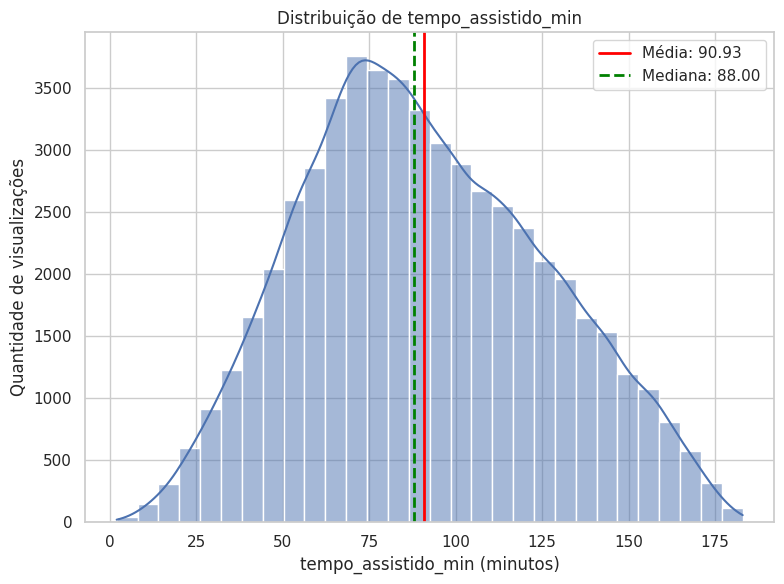

In [30]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("tempo_assistido_min (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de visualizações")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

O histograma mostra que a média do tempo assistido foi de 90,93 minutos e a mediana de 88 minutos. A proximidade entre os dois valores indica que as medidas de tendência central são semelhantes, com uma pequena diferença de 2,93 minutos.


###Boxplot

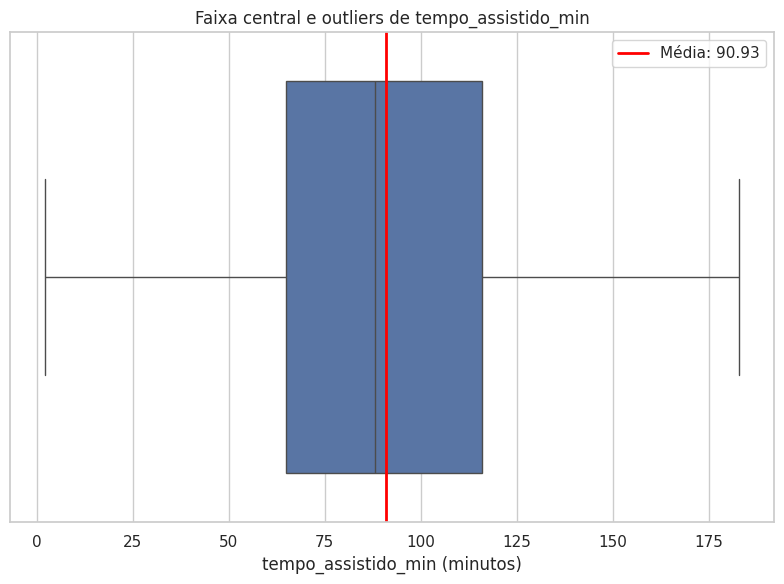

In [31]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("tempo_assistido_min (minutos)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()



O boxplot indica que não foram encontrados valores considerados outliers.

###Gráfico de barras

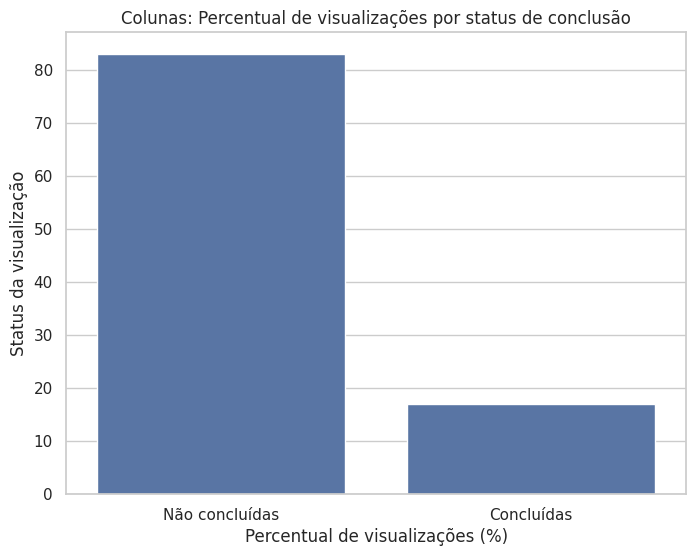

In [32]:

sns.barplot(data=resultado, x=resultado.index, y="percentual", errorbar=None)
plt.title("Colunas: Percentual de visualizações por status de conclusão")
plt.ylabel("Status da visualização")
plt.xlabel("Percentual de visualizações (%)")
plt.show()

Com o gráfico de barras é possível visualizar o alto número de visualizações não concluídas, que é de 82.98%.